# El sustituto aprendido frente al motor en el punto de referencia: codificación, onnxruntime y el error por salida

**Pregunta:** ¿Qué tan de cerca reproduce el sustituto neuronal publicado al motor en el caso de referencia S01, cuál de sus diez salidas es la peor, y qué responde el producto cuando el modelo no está?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 del tema 01-getting-started
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook usted puede:

- cargar un paquete de modelo publicado con el cargador validador del pipeline, y decir qué comprueba;
- codificar un punto de operación como lo espera la red y correr su grafo ONNX con onnxruntime;
- decodificar las diez salidas y compararlas con las del motor, salida por salida;
- ver qué devuelve el pipeline cuando falta un paquete, y por qué esa respuesta va rotulada.

## Preparación

Este tema agrega onnxruntime, que corre los grafos publicados, y jsonschema, que el cargador usa para validar el contrato de cada modelo contra su esquema.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

Las importaciones son las funciones de paquetes de modelo del pipeline, la codificación de características, el motor y los rangos de la barrida que definen el dominio de entrenamiento del sustituto. La celda imprime las cuatro versiones.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.bundles import load_bundle, session_for, decode_outputs, engine_outputs, surrogate_predict, released_slots, SURROGATE_OUTPUTS
from pipeline.model.crusher import Operating, evaluate
from pipeline.model.crusher.encoding import encode_input
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Datos

El caso de referencia S01, y el sustituto publicado: su contrato y sus dos grafos, uno float32 y uno cuantizado a 8 bits. El sustituto y el autoencoder son modelos publicados de ChancaDEM, entrenados por el propio pipeline con una barrida de hipercubo latino del motor y versionados con sus contratos (`surrogate-model`, `anomaly-model`). Clase de licencia: MIT, como el resto del repositorio; los datos de entrenamiento son sintéticos, sorteados del motor. Archivos leídos: `data/derived/manifests/S01.json`, `data/derived/models/surrogate.json`, `data/derived/models/surrogate.onnx` y `data/derived/models/surrogate.int8.onnx`.

La celda lee el punto de operación y fija la carpeta de modelos.

In [2]:
# Lea el punto de operación de S01 y fije la carpeta de los modelos publicados
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
models_dir = ROOT / "data" / "derived" / "models"
print(op.machine, op.css_mm, op.throw_mm, op.speed_rpm, op.feed_x63_mm, op.feed_m, op.ore_axb)

cone-sec 32.0 30.0 360.0 90.0 1.2 55.0


## Método

**Paso 1, el paquete.** Un modelo está publicado cuando su contrato JSON valida contra su esquema, sus vectores de estandarización son coherentes, y cada grafo que nombra existe con el tamaño en bytes y el resumen SHA-256 que registra el contrato. `load_bundle` hace todo eso y levanta un error que nombra el archivo cuando falla alguna comprobación, de modo que un grafo alterado nunca se sirve en silencio. La celda carga el paquete del sustituto e imprime lo que dice el contrato: la arquitectura, las entradas y salidas, y el tamaño y el resumen de cada grafo.

In [3]:
# Cargue el paquete validado del sustituto e imprima lo que declara su contrato
bundle = load_bundle("surrogate-model", models_dir)
print("espacios publicados:", released_slots(models_dir))
print("arquitectura:", bundle["architecture"].split(";")[0])
print("entradas:", bundle["machine_order"], bundle["input_order"])
print("salidas:", bundle["output_order"])
for kind, graph in bundle["graphs"].items():
    print(f"{kind:8s} {graph['bytes']:6d} bytes  sha256 {graph['sha256'][:12]}...")

espacios publicados: {'surrogate-model': True, 'anomaly-model': True}
arquitectura: 11-64-64-32-10 MLP, GELU
entradas: ['cone-sec', 'cone-tert', 'jaw', 'cone-short-head', 'gyratory'] ['css_mm', 'throw_mm', 'speed_rpm', 'feed_x63_mm', 'feed_m', 'ore_axb']
salidas: ['p80_mm', 'p50_mm', 'p20_mm', 'pass_1', 'pass_4', 'pass_8', 'pass_16', 'pass_32', 'throughput_tph', 'power_kw']
float32   32449 bytes  sha256 233024c3fb93...
int8      15880 bytes  sha256 34f70a8dca3b...


**Paso 2, la codificación.** La red recibe 11 números: un código one-hot del tipo de máquina (cinco columnas, en el orden del contrato) seguido de las seis entradas continuas, cada una estandarizada con la media y la desviación estándar que guardó el entrenamiento, $(x - \mu)/\sigma$. Equivocarse aquí es silencioso, porque la red siempre devuelve algo; por eso el codificador es una función del pipeline compartida por el entrenamiento, la evaluación y el puerto web, y el notebook la llama y nunca escribe la suya. La celda codifica S01 e imprime el vector junto a las entradas crudas.

In [4]:
# Codifique S01 como lo espera la red e imprima los 11 números
vector = encode_input(op, bundle["in_mean"], bundle["in_std"])
print("one-hot (cone-sec, cone-tert, jaw, cone-short-head, gyratory):", vector[:5])
for name, raw, z in zip(bundle["input_order"], (op.css_mm, op.throw_mm, op.speed_rpm, op.feed_x63_mm, op.feed_m, op.ore_axb), vector[5:]):
    print(f"{name:12s} raw {raw:7.2f}  standardised {z:+.3f}")

one-hot (cone-sec, cone-tert, jaw, cone-short-head, gyratory): [1.0, 0.0, 0.0, 0.0, 0.0]
css_mm       raw   32.00  standardised -0.479
throw_mm     raw   30.00  standardised +0.389
speed_rpm    raw  360.00  standardised +0.032
feed_x63_mm  raw   90.00  standardised -0.496
feed_m       raw    1.20  standardised -0.334
ore_axb      raw   55.00  standardised -0.683


**Paso 3, una corrida.** La celda abre una sesión de onnxruntime sobre el grafo float32, entrega el vector codificado con el nombre de entrada que da el contrato y decodifica las diez salidas estandarizadas a unidades de ingeniería: $y = z\,\sigma + \mu$, y una potencia de diez para las tres salidas de tamaño, que se ajustaron en escala logarítmica por positividad. Luego pide al motor los mismos diez números e imprime ambos con la diferencia relativa.

In [5]:
# Corra el grafo float32 en S01, decodifique sus salidas y póngalas junto a las del motor
session = session_for(models_dir, bundle["graphs"]["float32"])
z = session.run(None, {"x": np.array([vector], np.float32)})[0]
network = dict(zip(bundle["output_order"], decode_outputs(z, bundle)[0]))
teacher = engine_outputs(evaluate(op))
errors = {k: (network[k] - teacher[k]) / teacher[k] * 100 for k in SURROGATE_OUTPUTS}
for k in SURROGATE_OUTPUTS:
    print(f"{k:15s} red {network[k]:9.3f}  motor {teacher[k]:9.3f}  error {errors[k]:+6.2f} %")
print("error absoluto medio:", round(float(np.mean(np.abs(list(errors.values())))), 2), "%")

p80_mm          red    27.505  motor    27.698  error  -0.70 %
p50_mm          red    11.795  motor    12.090  error  -2.44 %
p20_mm          red     1.789  motor     1.829  error  -2.21 %
pass_1          red     0.148  motor     0.150  error  -1.45 %
pass_4          red     0.277  motor     0.288  error  -3.92 %
pass_8          red     0.393  motor     0.403  error  -2.48 %
pass_16         red     0.612  motor     0.579  error  +5.66 %
pass_32         red     0.838  motor     0.869  error  -3.57 %
throughput_tph  red   655.002  motor   643.158  error  +1.84 %
power_kw        red   275.587  motor   287.399  error  -4.11 %
error absoluto medio: 2.84 %


La figura dibuja los diez errores relativos. A una red se le suele juzgar con un solo número, su R cuadrado; aquí lo que importa es la dispersión de sus errores entre salidas.

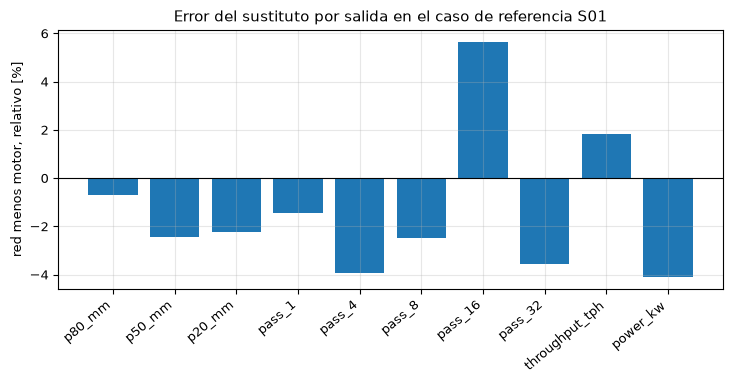

In [6]:
# Gráfico de barras del error relativo del sustituto por salida en S01
fig, ax = plt.subplots()
ax.bar(range(10), [errors[k] for k in SURROGATE_OUTPUTS])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(10), SURROGATE_OUTPUTS, rotation=40, ha="right")
ax.set_ylabel("red menos motor, relativo [%]")
ax.set_title("Error del sustituto por salida en el caso de referencia S01")
fig.tight_layout()
plt.show()

Los errores son pequeños y de signos mezclados: el mayor es +5,66 por ciento en `pass_16`, la fracción del producto más fina que 16 mm, y el menor es -0,70 por ciento en P80, la cantidad que más le importa a una planta. Nada en la figura dice que los errores en S01 representen los errores en otras partes: es un punto, elegido por su familiaridad, y la muestra retenida del notebook 02 es lo que mide el caso típico. Tampoco muestra la estructura de los signos, que aquí parece aleatoria y no está garantizada.

**Paso 4, la respuesta a una curva.** La abertura es la palanca que más mueve un usuario. La celda barre la abertura de lado cerrado de S01 de 8 a 60 mm y dibuja el P80 de la red y del motor, pidiéndoselo al ayudante del pipeline `surrogate_predict`, que carga el paquete, codifica, corre y decodifica en una llamada y dice qué proveniencia respondió.

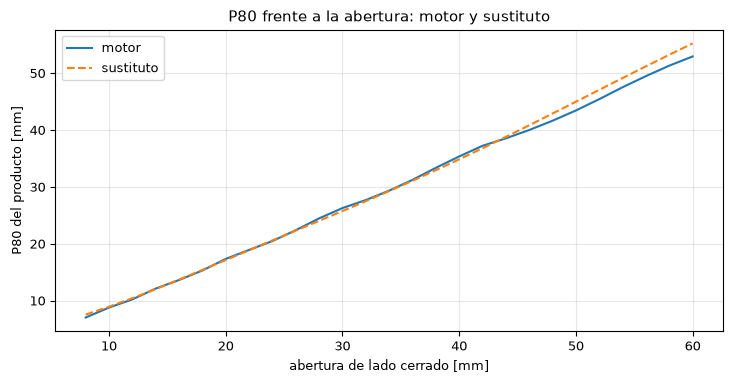

proveniencia de la respuesta: real | la curva no decrece: True


In [7]:
# Barra la abertura de S01 y dibuje el P80 de la red (por el ayudante del pipeline) y del motor
from dataclasses import replace

settings = np.linspace(8, 60, 27)
curve_network = [surrogate_predict(replace(op, css_mm=float(c)), models_dir)[0]["p80_mm"] for c in settings]
curve_engine = [evaluate(replace(op, css_mm=float(c))).p80 for c in settings]
fig, ax = plt.subplots()
ax.plot(settings, curve_engine, label="motor")
ax.plot(settings, curve_network, "--", label="sustituto")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("P80 del producto [mm]")
ax.set_title("P80 frente a la abertura: motor y sustituto")
ax.legend()
fig.tight_layout()
plt.show()
print("proveniencia de la respuesta:", surrogate_predict(op, models_dir)[1], "| la curva no decrece:", bool(np.all(np.diff(curve_network) > -1e-3)))

Las dos curvas se superponen a simple vista y la de la red es monótona, la propiedad física que el producto prueba en cada máquina. La desviación es mayor en el extremo ancho del rango, sobre una abertura de 45 mm, donde la red queda sobre el motor hasta en unos 2 mm. Lo que no muestra es la parte del espacio donde no hay datos de entrenamiento, que visita el notebook 03.

**Paso 5, cuando el modelo no está.** La regla del producto para un paquete ausente o inválido es que responde el motor, con la proveniencia rotulada `baseline`, de modo que un resultado nunca se presenta como de la red cuando no lo es. La celda apunta el ayudante a una carpeta sin modelo e imprime lo que devuelve para el mismo punto de operación, junto a la respuesta con el paquete real.

In [8]:
# Pida el mismo punto con el paquete real y con una carpeta que no contiene modelo
real_answer, real_provenance = surrogate_predict(op, models_dir)
missing_answer, missing_provenance = surrogate_predict(op, ROOT / "no-such-models-folder")
print("paquete real   :", real_provenance, round(real_answer["p80_mm"], 3), "mm de P80")
print("paquete ausente:", missing_provenance, round(missing_answer["p80_mm"], 3), "mm de P80 (el valor propio del motor)")
print("espacios publicados con la carpeta ausente:", released_slots(ROOT / "no-such-models-folder"))

paquete real   : real 27.505 mm de P80
paquete ausente: baseline 27.698 mm de P80 (el valor propio del motor)
espacios publicados con la carpeta ausente: {'surrogate-model': False, 'anomaly-model': False}


## Resultados

**Respuesta:** en S01 el sustituto reproduce las diez salidas del motor con un error absoluto medio de 2,84 por ciento, desde -0,70 por ciento en P80 hasta +5,66 por ciento en `pass_16`, y su curva de P80 frente a la abertura es monótona y se superpone a la del motor. Cuando falta el paquete el ayudante devuelve el valor propio del motor, 27,698 mm, con la proveniencia `baseline`, en lugar de los 27,505 mm de la red rotulados `real`, y los dos espacios publicados figuran como no publicados.

La figura de errores no muestra ninguna salida con un error grande en este punto; la barrida muestra que la red sigue la forma del motor a lo largo de la abertura. Un validador concluiría que la red publicada es un emulador fiel del motor cerca del caso de referencia, y que la negativa del producto a hacer pasar un valor del motor por uno de la red está implementada y es comprobable. Esto aún no dice cómo se comporta con el punto retenido promedio, ni lejos del dominio de entrenamiento, ni frente a una planta real: el notebook 02 y el notebook 03 los toman por turno.

## Resumen

Un modelo publicado es un contrato, un grafo y un resumen; el cargador valida los tres y el ayudante rotula lo que respondió. La red emula al motor en S01 con cerca de 3 por ciento, peor en la fracción más fina que 16 mm. El notebook 02 la mide con una muestra retenida de 2196 puntos de operación de las cinco máquinas, y pregunta al segundo modelo publicado, el autoencoder, qué detecta.

## Referencias

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193